# Forty-eight hours before kick-off: Fan arrivals at the 2026 World Cup host airports

Replication notebook. It reproduces every number, the table and the two figures of the paper from `data/daily_by_airport.csv` (daily counts built from the U.S. Customs and Border Protection Airport Wait Times data) and `data/wc2026_matches.csv` (the match schedule).

Run all cells. With `DOWNLOAD = True` the daily file is first rebuilt from the CBP site (about 30 minutes); otherwise the copy in the repository is used. Outputs are written to `output/`.

In [1]:
import os, io, re, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy import optimize
import statsmodels.formula.api as smf
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

DOWNLOAD = False                       # True rebuilds data/daily_by_airport.csv from awt.cbp.gov
START, END = '2023-05-03', '2026-10-06'  # sample used in the paper
REPO = 'https://raw.githubusercontent.com/manueleleonelli/worldcup2026-arrivals/main/'
os.makedirs('data', exist_ok=True); os.makedirs('output', exist_ok=True)

HOST_AIRPORTS = {
    'New York/New Jersey': ['JFK', 'EWR'],
    'Los Angeles': ['LAX', 'ONT', 'SNA'],
    'San Francisco Bay Area': ['SFO', 'SJC', 'OAK'],
    'Miami': ['MIA', 'FLL'],
    'Atlanta': ['ATL'], 'Seattle': ['SEA'], 'Dallas': ['DFW'],
    'Houston': ['IAH'], 'Boston': ['BOS'], 'Philadelphia': ['PHL'],
}
MAJOR = ['New York/New Jersey', 'Los Angeles', 'San Francisco Bay Area', 'Miami']
SECONDARY = ['Atlanta', 'Seattle', 'Dallas', 'Houston', 'Boston', 'Philadelphia']
HOSTS = MAJOR + SECONDARY
COMPARISON = ['ORD', 'IAD', 'BWI', 'CLT', 'RDU', 'DTW', 'MSP', 'CVG', 'STL', 'DEN',
              'SLC', 'PHX', 'LAS', 'SAN', 'PDX', 'HNL', 'MCO', 'TPA', 'AUS', 'SAT']
AREA = {a: m for m, v in HOST_AIRPORTS.items() for a in v}
AREA.update({a: a for a in COMPARISON})
TOURN_START, TOURN_END = pd.Timestamp('2026-06-11'), pd.Timestamp('2026-07-19')

def load(name, **kw):
    local = os.path.join('data', name)
    return pd.read_csv(local if os.path.exists(local) else REPO + 'data/' + name, **kw)

## 1. Data

### Optional: rebuild the daily file from CBP

The CBP site serves hourly records per airport and terminal through a JSON endpoint, from 3 May 2023 onwards. Airports not in the CBP system return 404 and are skipped.

In [2]:
def fetch(code, start=START, end=END):
    import requests
    frames = []
    for s in pd.date_range(start, end, freq='365D'):
        e = min(s + pd.Timedelta(days=364), pd.Timestamp(end))
        payload = json.dumps({'Id': code, 'FromDate': s.strftime('%Y-%m-%d'), 'ToDate': e.strftime('%Y-%m-%d')})
        for k in range(3):
            try:
                r = requests.post('https://awt.cbp.gov/api/waitTime', data=payload, timeout=180,
                                  headers={'Content-Type': 'application/json', 'Accept': 'application/json'})
                if r.status_code == 404:
                    return pd.DataFrame()
                if r.status_code == 200:
                    js = r.json(); items = js.get('Items', []) if isinstance(js, dict) else js
                    if items: frames.append(pd.json_normalize(items))
                    break
            except Exception:
                pass
            time.sleep(3 * (k + 1))
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def find_col(cols, patterns, exclude=None):
    for p in patterns:
        for c in cols:
            if re.search(p, c, re.I) and not (exclude and re.search(exclude, c, re.I)):
                return c

def to_daily(code, df):
    cols = list(df.columns)
    m = {'date': find_col(cols, [r'flight.?date', r'date']),
         'usa': find_col(cols, [r'^usa.*passeng', r'usa.*count'], r'non|wait|excl'),
         'nonusa': find_col(cols, [r'non.?usa.*passeng', r'non.?us.*count'], r'wait|excl'),
         'total': find_col(cols, [r'(all|total).*passeng', r'total.*count'], r'wait|usa|excl'),
         'flights': find_col(cols, [r'flight.*count'], r'date'),
         'nonusa_max': find_col(cols, [r'non.?usa.*max.*wait', r'non.?us.*max']),
         'usa_max': find_col(cols, [r'^usa.*max.*wait'], r'non'),
         'all_max': find_col(cols, [r'all.*max.*wait', r'max.*wait'], r'usa'),
         'nonusa_avg': find_col(cols, [r'non.?usa.*(avg|average).*wait', r'non.?us.*(avg|average)']),
         'all_avg': find_col(cols, [r'all.*(avg|average).*wait', r'(avg|average).*wait'], r'usa')}
    t = pd.DataFrame({'airport': code, 'date': pd.to_datetime(df[m['date']], errors='coerce').dt.normalize()})
    for k in m:
        if k != 'date':
            t[k] = pd.to_numeric(df[m[k]], errors='coerce') if m[k] else np.nan
    t['_wn'] = t.nonusa_avg * t.nonusa; t['_wa'] = t.all_avg * t.total
    d = t.dropna(subset=['date']).groupby(['airport', 'date']).agg(
        usa=('usa', 'sum'), nonusa=('nonusa', 'sum'), total=('total', 'sum'), flights=('flights', 'sum'),
        nonusa_max_wait=('nonusa_max', 'max'), usa_max_wait=('usa_max', 'max'), all_max_wait=('all_max', 'max'),
        _wn=('_wn', 'sum'), _wa=('_wa', 'sum')).reset_index()
    d['nonusa_avg_wait'] = d._wn / d.nonusa.replace(0, np.nan); d['all_avg_wait'] = d._wa / d.total.replace(0, np.nan)
    return d.drop(columns=['_wn', '_wa'])

if DOWNLOAD:
    parts = []
    for code_ in sorted(AREA):
        raw = fetch(code_)
        print(code_, len(raw), 'hourly rows')
        if len(raw): parts.append(to_daily(code_, raw))
    pd.concat(parts).sort_values(['airport', 'date']).to_csv('data/daily_by_airport.csv', index=False)

### Daily series by area and match schedule

In [3]:
airport = load('daily_by_airport.csv', parse_dates=['date'])
airport = airport[(airport.date >= START) & (airport.date <= END) & airport.airport.isin(AREA)]
airport['area'] = airport.airport.map(AREA)
daily = airport.groupby(['area', 'date']).agg(
    nonusa=('nonusa', 'sum'), total=('total', 'sum'), nonusa_max_wait=('nonusa_max_wait', 'max')).reset_index()
full = pd.MultiIndex.from_product([daily.area.unique(), pd.date_range(START, END)], names=['area', 'date'])
daily = daily.set_index(['area', 'date']).reindex(full).reset_index()

matches = load('wc2026_matches.csv', parse_dates=['date'])
us = matches[matches.metro.isin(HOSTS)]
match_dates = {m: sorted(g.date) for m, g in us.groupby('metro')}
window_days = {m: {x for d in ds for x in pd.date_range(d - pd.Timedelta(days=2), d + pd.Timedelta(days=1))}
               for m, ds in match_dates.items()}

print(airport.airport.nunique(), 'airports,', daily.area.nunique(), 'areas,', daily.date.nunique(), 'days')
print(len(us), 'of', (matches.country == 'US').sum(), 'US matches covered')
avg = daily.groupby('area').nonusa.mean().round(0)
print('Average daily non-US arrivals by host area:'); print(avg[HOSTS].sort_values(ascending=False).to_string())

36 airports, 30 areas, 1253 days
72 of 78 US matches covered
Average daily non-US arrivals by host area:
area
New York/New Jersey       27926.0
Miami                     19778.0
Los Angeles               13848.0
San Francisco Bay Area     8994.0
Houston                    6386.0
Dallas                     5509.0
Atlanta                    5223.0
Boston                     3638.0
Seattle                    3083.0
Philadelphia                824.0


## 2. Year-on-year comparison and peak rank (Table 1, columns 2 and 3)

In [4]:
def window_sum(areas, year):
    d0, d1 = TOURN_START.replace(year=year), TOURN_END.replace(year=year)
    return daily[daily.area.isin(areas) & (daily.date >= d0) & (daily.date <= d1)].nonusa.sum()

rows = []
for m in HOSTS:
    d = daily[daily.area == m].dropna(subset=['nonusa'])
    hist, tw = d[d.date < TOURN_START], d[(d.date >= TOURN_START) & (d.date <= TOURN_END)]
    pk = tw.loc[tw.nonusa.idxmax()]
    rows.append({'area': m, 'matches': len(match_dates[m]),
                 'change_pct': 100 * (window_sum([m], 2026) / window_sum([m], 2025) - 1),
                 'peak_rank': int((hist.nonusa >= pk.nonusa).sum()) + 1, 'peak_date': pk.date.date(),
                 'peak_vs_previous_max_pct': 100 * (pk.nonusa / hist.nonusa.max() - 1)})
desc = pd.DataFrame(rows).set_index('area')
groups = {'Major gateways': MAJOR, 'Secondary hosts': SECONDARY, 'All hosts': HOSTS, 'Comparison airports': COMPARISON}
group_change = {g: 100 * (window_sum(a, 2026) / window_sum(a, 2025) - 1) for g, a in groups.items()}
print('Pre-tournament days:', daily[daily.date < TOURN_START].date.nunique())
print('Host total in the tournament window: %.0f' % window_sum(HOSTS, 2026))
display(desc.round(1)); print({g: round(v, 1) for g, v in group_change.items()})

Pre-tournament days: 1135
Host total in the tournament window: 3788497


,matches,change_pct,peak_rank,peak_date,peak_vs_previous_max_pct
area,,,,,
New York/New Jersey,8,-6.8,160,2026-06-12,-25.4
Los Angeles,8,2.1,74,2026-07-17,-22.6
San Francisco Bay Area,6,-1.8,139,2026-07-18,-20.2
Miami,7,-1.8,88,2026-07-10,-27.8
Atlanta,8,0.7,53,2026-07-14,-22.5
Seattle,6,-2.3,25,2026-07-12,-8.0
Dallas,9,23.8,4,2026-07-13,-11.5
Houston,7,11.5,23,2026-06-22,-17.5
Boston,7,11.8,1,2026-06-11,15.5


{'Major gateways': np.float64(-3.1), 'Secondary hosts': np.float64(9.9), 'All hosts': np.float64(0.3), 'Comparison airports': np.float64(-0.5)}


## 3. Synthetic control (Table 1, columns 4 to 6, and Figure 1)

Weekly log non-US arrivals. The synthetic control of a host is a weighted average of the comparison airports (non-negative weights summing to one) plus a constant, fitted on January 2023 to the week before the tournament. The gap over the six tournament weeks gives the uplift and the excess arrivals. Each comparison airport is then treated in turn as a placebo, and the host's post/pre ratio of root mean squared prediction error is ranked among the twenty airports. Cincinnati has gaps in its weekly series and is excluded from this step.

In [5]:
daily['week'] = daily.date - pd.to_timedelta(daily.date.dt.weekday, unit='D')
wk = daily.groupby(['area', 'week']).agg(nonusa=('nonusa', 'sum'), n=('nonusa', 'count')).reset_index()
wk = wk[wk.n == 7]
W = np.log(wk.pivot(index='week', columns='area', values='nonusa').loc['2023-01-02':].replace(0, np.nan))
PRE_END = pd.Timestamp('2026-06-01')
TW = pd.date_range('2026-06-08', '2026-07-13', freq='7D')
donors = [a for a in COMPARISON if W[a].loc[:PRE_END].notna().mean() > 0.9]
print(len(donors), 'comparison airports used; excluded:', [a for a in COMPARISON if a not in donors])

def synth(y, D):
    ybar, Dbar = y.mean(), D.mean(axis=0); Y, X = y - ybar, D - Dbar; J = X.shape[1]
    res = optimize.minimize(lambda w: np.sum((Y - X @ w) ** 2), np.ones(J) / J, bounds=[(0, 1)] * J,
                            constraints=({'type': 'eq', 'fun': lambda w: w.sum() - 1},), method='SLSQP',
                            options={'maxiter': 2000, 'ftol': 1e-12})
    w = np.clip(res.x, 0, None); w[w < 1e-4] = 0; w /= w.sum()
    return w, ybar - Dbar @ w

def run_sc(unit, pool):
    M = W[[unit] + pool].dropna(); pre = M[M.index <= PRE_END]; post = M.index.isin(TW)
    w, a = synth(pre[unit].values, pre[pool].values)
    syn = pd.Series(M[pool].values @ w + a, index=M.index); gap = M[unit] - syn
    return dict(w=pd.Series(w, index=pool), syn=syn, obs=M[unit],
                ratio=np.sqrt((gap[post] ** 2).mean()) / np.sqrt((gap[M.index <= PRE_END] ** 2).mean()),
                uplift=100 * (np.exp(gap[post].mean()) - 1),
                excess=(np.exp(M[unit][post]) - np.exp(syn[post])).sum())

placebo = [run_sc(a, [b for b in donors if b != a])['ratio'] for a in donors]
sc, rows = {}, []
for m in HOSTS:
    r = run_sc(m, donors); sc[m] = r
    rows.append({'area': m, 'uplift_pct': r['uplift'], 'excess_thousands': r['excess'] / 1000,
                 'rank_of_20': int(np.sum(np.array(placebo) >= r['ratio'])) + 1})
sctab = pd.DataFrame(rows).set_index('area')
weights = pd.DataFrame({m: sc[m]['w'] for m in HOSTS}).T.round(3)
weights.to_csv('output/synthetic_control_weights.csv')
display(sctab.round(1))
print('Excess (thousands): major %.0f, secondary %.0f, all %.0f' % (
    sctab.loc[MAJOR].excess_thousands.sum(), sctab.loc[SECONDARY].excess_thousands.sum(), sctab.excess_thousands.sum()))
print('\nLargest weights:')
for m in HOSTS:
    print('  %-24s' % m, ', '.join(f'{k} {v:.2f}' for k, v in weights.loc[m].sort_values(ascending=False).head(3).items()))

19 comparison airports used; excluded: ['CVG']


,uplift_pct,excess_thousands,rank_of_20
area,,,
New York/New Jersey,-4.8,-58.6,4
Los Angeles,1.4,7.5,11
San Francisco Bay Area,-4.4,-17.5,5
Miami,-5.5,-45.3,6
Atlanta,-3.2,-7.5,8
Seattle,7.2,10.4,8
Dallas,15.4,34.8,1
Houston,4.8,12.2,1
Boston,18.9,31.3,1


Excess (thousands): major -114, secondary 89, all -25

Largest weights:
  New York/New Jersey      IAD 0.48, HNL 0.16, SAT 0.11
  Los Angeles              HNL 0.25, IAD 0.23, LAS 0.14
  San Francisco Bay Area   DTW 0.26, IAD 0.15, ORD 0.14
  Miami                    PHX 0.38, HNL 0.29, SAT 0.14
  Atlanta                  IAD 0.31, PHX 0.29, DTW 0.12
  Seattle                  PDX 0.20, MSP 0.19, DTW 0.19
  Dallas                   PHX 0.31, IAD 0.26, HNL 0.22
  Houston                  IAD 0.33, PHX 0.23, HNL 0.21
  Boston                   ORD 0.46, MSP 0.22, IAD 0.14
  Philadelphia             MSP 0.55, CLT 0.30, BWI 0.05


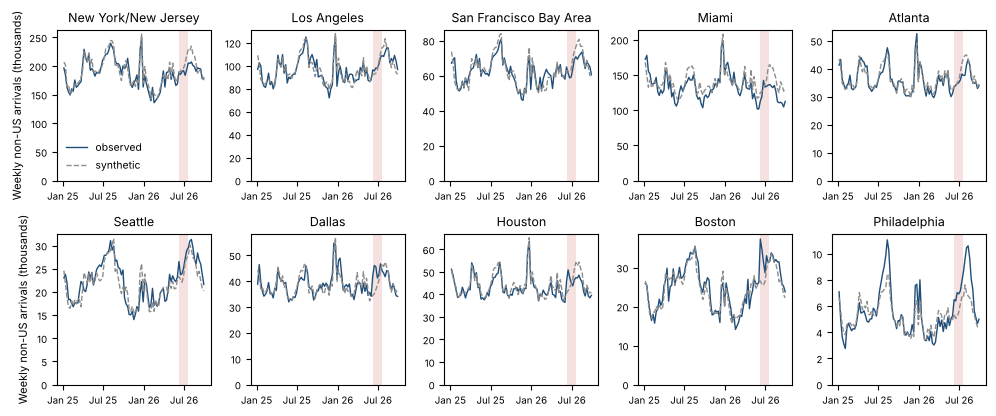

In [6]:
plt.rcParams.update({'font.size': 8, 'axes.titlesize': 9, 'legend.fontsize': 7.5})
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for ax, m in zip(axes.flat, HOSTS):
    r = sc[m]; idx = r['obs'].loc['2025-01-01':].index
    ax.plot(idx, np.exp(r['obs'].loc[idx]) / 1000, color='#1f4e79', lw=1.0, label='observed')
    ax.plot(idx, np.exp(r['syn'].loc[idx]) / 1000, color='#8c8c8c', lw=1.0, ls='--', label='synthetic')
    ax.axvspan(TW[0], TW[-1] + pd.Timedelta(days=6), color='#c0392b', alpha=0.15, lw=0)
    ax.set_title(m); ax.set_ylim(0, None); ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
axes[0, 0].legend(frameon=False, loc='lower left')
for ax in axes[:, 0]: ax.set_ylabel('Weekly non-US arrivals (thousands)')
fig.tight_layout(); fig.savefig('output/figure1_synthetic.pdf'); fig.savefig('output/figure1_synthetic.png', dpi=200); plt.show()

### Pooled weekly regression and week-by-week effects

In [7]:
lw = W.loc[:TW[-1] + pd.Timedelta(weeks=8)].stack().rename('ly').reset_index(); lw.columns = ['week', 'area', 'ly']; lw = lw.dropna()
lw['host'] = lw.area.isin(HOSTS).astype(int); lw['tourn'] = lw.week.isin(TW).astype(int); lw['post'] = (lw.week > TW[-1]).astype(int)
f = smf.ols('ly ~ C(area) + C(week) + host:tourn + host:post', data=lw).fit(cov_type='cluster', cov_kwds={'groups': lw.area})
print('Pooled tournament-week effect: %.1f%% (SE %.1f percentage points)' % (100 * (np.exp(f.params['host:tourn']) - 1), 100 * f.bse['host:tourn']))
for k, w in enumerate(TW, 1): lw[f'h{k}'] = ((lw.week == w) & (lw.host == 1)).astype(int)
f2 = smf.ols('ly ~ C(area) + C(week) + ' + ' + '.join(f'h{k}' for k in range(1, 7)) + ' + host:post', data=lw).fit(
    cov_type='cluster', cov_kwds={'groups': lw.area})
es = pd.DataFrame({'week_start': TW.date, 'effect_pct': [100 * (np.exp(f2.params[f'h{k}']) - 1) for k in range(1, 7)],
                   'se_pp': [100 * f2.bse[f'h{k}'] for k in range(1, 7)]})
es.to_csv('output/weekly_effects.csv', index=False); display(es.round(1))

Pooled tournament-week effect: -5.1% (SE 5.6 percentage points)


,week_start,effect_pct,se_pp
0,2026-06-08,0.3,7.2
1,2026-06-15,1.2,6.1
2,2026-06-22,-0.7,5.4
3,2026-06-29,-8.1,5.9
4,2026-07-06,-10.5,6.1
5,2026-07-13,-11.6,5.8


## 4. Daily match-window regression (Table 1, columns 7 and 8, and Figure 2)

$\log y_{it} = \alpha_i + \delta_t + \sum_j \beta_j W_{ijt} + \varepsilon_{it}$ for 1 May to 31 August, with $W_{ijt}=1$ on the match-window days of host $j$ (two days before a match to the day after). The 2025 placebo moves every match date back 364 days, onto the same weekday.

In [8]:
def design(year):
    shift = pd.Timedelta(days=364 * (2026 - year))
    d = daily[(daily.date >= f'{year}-05-01') & (daily.date <= f'{year}-08-31') & (daily.nonusa > 0)].copy()
    d['ly'] = np.log(d.nonusa); d['host'] = d.area.isin(HOSTS).astype(int)
    d['window'] = [int(m in window_days and (t + shift) in window_days[m]) for m, t in zip(d.area, d.date)]
    for i, m in enumerate(HOSTS): d[f'w{i}'] = ((d.area == m) & (d.window == 1)).astype(int)
    def rel(m, t):
        if m not in match_dates: return np.nan
        k = min([(t + shift - x).days for x in match_dates[m]], key=abs)
        return k if -5 <= k <= 4 else np.nan
    d['rel'] = [rel(m, t) for m, t in zip(d.area, d.date)]
    for k in range(-5, 5): d[f'r{k+5}'] = ((d.rel == k) & (d.host == 1)).astype(int)
    return d

res = {}
for year in (2026, 2025):
    d = design(year)
    per = smf.ols('ly ~ C(area) + C(date) + ' + ' + '.join(f'w{i}' for i in range(len(HOSTS))), data=d).fit(cov_type='HC1')
    pooled = smf.ols('ly ~ C(area) + C(date) + window', data=d).fit(cov_type='cluster', cov_kwds={'groups': d.area})
    prof = smf.ols('ly ~ C(area) + C(date) + ' + ' + '.join(f'r{k+5}' for k in range(-5, 5)), data=d).fit(
        cov_type='cluster', cov_kwds={'groups': d.area})
    res[year] = dict(
        per=pd.DataFrame({'effect_pct': [100 * (np.exp(per.params[f'w{i}']) - 1) for i in range(len(HOSTS))],
                          't': [per.params[f'w{i}'] / per.bse[f'w{i}'] for i in range(len(HOSTS))]}, index=HOSTS),
        pooled=(100 * (np.exp(pooled.params['window']) - 1), 100 * pooled.bse['window']),
        prof=pd.DataFrame({'day': range(-5, 5), 'b': [prof.params[f'r{k+5}'] for k in range(-5, 5)],
                           's': [prof.bse[f'r{k+5}'] for k in range(-5, 5)]}))
    print(year, 'pooled match-window effect: %.1f%% (SE %.1f percentage points)' % res[year]['pooled'])
mw = res[2026]['per'].join(res[2025]['per'], lsuffix='_2026', rsuffix='_2025'); display(mw.round(1))
profile = pd.DataFrame({'day': range(-5, 5), 'effect_2026_pct': 100 * (np.exp(res[2026]['prof'].b) - 1),
                        'effect_2025_pct': 100 * (np.exp(res[2025]['prof'].b) - 1)})
profile.to_csv('output/match_day_profile.csv', index=False); display(profile.round(1))

2026 pooled match-window effect: 8.2% (SE 2.9 percentage points)


2025 pooled match-window effect: 2.3% (SE 2.1 percentage points)


,effect_pct_2026,t_2026,effect_pct_2025,t_2025
New York/New Jersey,4.2,1.9,3.3,1.4
Los Angeles,3.4,1.6,2.2,1.1
San Francisco Bay Area,0.4,0.1,1.7,0.7
Miami,14.4,4.2,9.5,3.6
Atlanta,1.1,0.5,-1.7,-0.7
Seattle,-0.2,-0.0,11.9,4.1
Dallas,15.8,5.0,-0.7,-0.3
Houston,20.7,5.8,2.6,1.1
Boston,21.9,5.2,5.4,2.0
Philadelphia,1.0,0.2,-10.6,-2.0


,day,effect_2026_pct,effect_2025_pct
0,-5,-3.6,7.6
1,-4,4.7,6.0
2,-3,6.1,-0.8
3,-2,13.1,3.5
4,-1,16.4,2.8
5,0,2.4,1.7
6,1,4.7,1.5
7,2,-1.9,-1.1
8,3,2.2,1.2
9,4,-4.3,-3.1


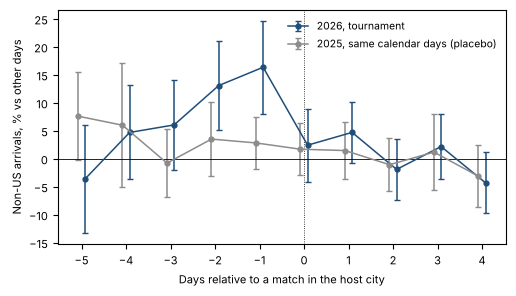

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 3.0))
for yr, c, lab, off in ((2026, '#1f4e79', '2026, tournament', 0.08), (2025, '#8c8c8c', '2025, same calendar days (placebo)', -0.08)):
    p = res[yr]['prof']
    ax.errorbar(p.day + off, 100 * (np.exp(p.b) - 1), yerr=100 * 1.96 * p.s, fmt='o-', color=c, ms=3.5, lw=1.1, capsize=2, label=lab)
ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6, ls=':')
ax.set_xlabel('Days relative to a match in the host city'); ax.set_ylabel('Non-US arrivals, % vs other days')
ax.set_xticks(range(-5, 5)); ax.legend(frameon=False, loc='upper right')
fig.tight_layout(); fig.savefig('output/figure2_profile.pdf'); fig.savefig('output/figure2_profile.png', dpi=200); plt.show()

## 5. Waiting times (Table 1, column 9)

Difference, in minutes, between the 90th percentile of the daily maximum non-US-citizen wait on match-window days and on other days of June and July 2026.

In [10]:
jj = daily[(daily.date.dt.year == 2026) & daily.date.dt.month.isin([6, 7]) & daily.area.isin(HOSTS)].dropna(subset=['nonusa_max_wait'])
jj['window'] = [t in window_days.get(m, set()) for m, t in zip(jj.area, jj.date)]
waits = jj.groupby(['area', 'window']).nonusa_max_wait.quantile(0.9).unstack()
waits['difference_min'] = waits[True] - waits[False]
waits['median_daily_max'] = jj.groupby('area').nonusa_max_wait.median()
display(waits.loc[HOSTS].round(0))

window,False,True,difference_min,median_daily_max
area,,,,
New York/New Jersey,186.0,195.0,8.0,147.0
Los Angeles,120.0,119.0,-0.0,93.0
San Francisco Bay Area,104.0,121.0,17.0,90.0
Miami,140.0,126.0,-13.0,103.0
Atlanta,91.0,85.0,-6.0,61.0
Seattle,152.0,141.0,-11.0,122.0
Dallas,118.0,125.0,8.0,78.0
Houston,133.0,128.0,-6.0,97.0
Boston,97.0,108.0,11.0,77.0


## 6. Table 1

In [11]:
t1 = desc[['matches', 'change_pct', 'peak_rank']].join(sctab).join(mw[['effect_pct_2026', 'effect_pct_2025']]).join(waits[['difference_min']])
t1 = t1.loc[HOSTS]
t1.to_csv('output/table1.csv')

def f(x, d=1):
    if pd.isna(x): return ''
    x = round(x, d) + 0.0
    if x == 0: x = 0.0
    s = f'{abs(x):.{d}f}' if x == 0 else f'{x:.{d}f}'
    return f'${s}$' if x < 0 else s

lines = []
for label, areas in (('Major gateways', MAJOR), ('Secondary hosts', SECONDARY)):
    lines.append(r'\multicolumn{10}{l}{\textit{%s}} \\' % label)
    for m in areas:
        r = t1.loc[m]
        lines.append(f"{m} & {int(r.matches)} & {f(r.change_pct)} & {int(r.peak_rank)} & {f(r.uplift_pct)} & {f(r.excess_thousands)} & "
                     f"{int(r.rank_of_20)} & {f(r.effect_pct_2026)} & {f(r.effect_pct_2025)} & {f(r.difference_min, 0)} \\\\")
    lines.append(f"\\quad Total & & {f(group_change[label])} & & & {f(t1.loc[areas].excess_thousands.sum())} & & & & \\\\")
lines.append(r'\midrule')
lines.append(f"All hosts & & {f(group_change['All hosts'])} & & & {f(t1.excess_thousands.sum())} & & "
             f"{f(res[2026]['pooled'][0])} & {f(res[2025]['pooled'][0])} & \\\\")
lines.append(f"Comparison airports & & {f(group_change['Comparison airports'])} & & & & & & & \\\\")
open('output/table1_rows.tex', 'w').write('\n'.join(lines) + '\n')
print('\n'.join(lines))

\multicolumn{10}{l}{\textit{Major gateways}} \\
New York/New Jersey & 8 & $-6.8$ & 160 & $-4.8$ & $-58.6$ & 4 & 4.2 & 3.3 & 8 \\
Los Angeles & 8 & 2.1 & 74 & 1.4 & 7.5 & 11 & 3.4 & 2.2 & 0 \\
San Francisco Bay Area & 6 & $-1.8$ & 139 & $-4.4$ & $-17.5$ & 5 & 0.4 & 1.7 & 17 \\
Miami & 7 & $-1.8$ & 88 & $-5.5$ & $-45.3$ & 6 & 14.4 & 9.5 & $-13$ \\
\quad Total & & $-3.1$ & & & $-113.8$ & & & & \\
\multicolumn{10}{l}{\textit{Secondary hosts}} \\
Atlanta & 8 & 0.7 & 53 & $-3.2$ & $-7.5$ & 8 & 1.1 & $-1.7$ & $-6$ \\
Seattle & 6 & $-2.3$ & 25 & 7.2 & 10.4 & 8 & $-0.2$ & 11.9 & $-11$ \\
Dallas & 9 & 23.8 & 4 & 15.4 & 34.8 & 1 & 15.8 & $-0.7$ & 8 \\
Houston & 7 & 11.5 & 23 & 4.8 & 12.2 & 1 & 20.7 & 2.6 & $-6$ \\
Boston & 7 & 11.8 & 1 & 18.9 & 31.3 & 1 & 21.9 & 5.4 & 11 \\
Philadelphia & 6 & 12.5 & 57 & 23.4 & 7.9 & 3 & 1.0 & $-10.6$ & $-1$ \\
\quad Total & & 9.9 & & & 89.0 & & & & \\
\midrule
All hosts & & 0.3 & & & $-24.8$ & & 8.2 & 2.3 & \\
Comparison airports & & $-0.5$ & & & & & & & \\
